# 12 · Quick Plot

Turning a column into a chart in one line with pandas' built-in plot.

In [1]:
# Setup: the steps from the previous parts (run this first)
import pandas as pd
pd.set_option("display.max_colwidth", 30)

URL = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
       "master/data/2021/2021-04-20/netflix_titles.csv")
df = pd.read_csv(URL)

df = df.drop(columns=["cast", "description"])

df["director"] = df["director"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df = df.dropna(subset=["date_added", "rating"])

df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month_name()
df["duration_num"] = df["duration"].str.split(" ").str[0].astype(int)
df["main_country"] = df["country"].str.split(", ").str[0]

df["years_to_netflix"] = df["year_added"] - df["release_year"]
movies = df[df["type"] == "Movie"].assign(hours=pd.col("duration_num") / 60)

<Axes: title={'center': 'Titles added per year'}, xlabel='year_added'>

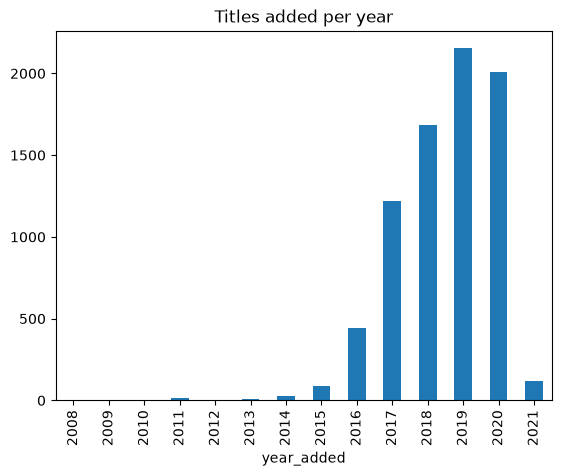

In [2]:
df["year_added"].value_counts().sort_index().plot(kind="bar", title="Titles added per year")